# The turn map hides a clock

Can two fields give the ant the same next turn at **every cell**, yet produce
different returns to the boundary? This excluded pilot changes hidden colour
phases once, preserves depth-bin colour counts, and then uses full-memory dynamics.

**Outcome: the registered comparison is unresolved.** P1 failed in two of six
rule/area comparisons; 17 of 24 start/area groups lacked eight long episodes.
The narrower same-map/different-return observation survives. This is not an
occupation forecast or a derivation of cube-root growth.

## Protocol and assumptions

Three rules, four new 5x5-patch seeds each (2026102301–2026102304); area bands
[4096,4352) and [16384,17408). Select the first 16 returns of at least 128 steps,
with the registered gap. Shuffle interior colours within depth/8 bins and shared
future-turn words of length 0, 1, 2, 4, or the entire rule. Four replicas per arm.
Boundary cells and territory stay fixed; cap 2^18.

Preserving k turns prevents path divergence before read k+1 at the first differing
cell. That coupling idea predates this pilot in the c-law renewal record.
The new contribution is a measured histogram-preserving field intervention,
with complete baseline eligibility accounting.

Read README.md for the preregistered thresholds, source links and exact commands.

In [1]:
from pathlib import Path
import hashlib, importlib.util, json
from IPython.display import Markdown, Image, display

root = Path.cwd()
if not (root / 'Cargo.toml').exists():
    root = next(p for p in root.parents if (p / 'Cargo.toml').exists())
here = root / 'experiments/2026-10-23-hidden-phase-return'
manifest = json.loads((here / 'results/run.done.json').read_text())
for name, digest in manifest['output_hashes'].items():
    assert hashlib.sha256((here / 'results' / name).read_bytes()).hexdigest() == digest
print('Instrument revision:', manifest['revision'])
print('Binary SHA256:', manifest['binary_sha256'])
print('Verified CSV hashes:', len(manifest['output_hashes']))
print(manifest['thread_replication'])


Instrument revision: bcfceeb7edd4598fd5c88022dac73e68515e707c
Binary SHA256: 7f06968cc776a9a45292199587e97ad9ddd6bef23dc1c54efb6fd77665945b67
Verified CSV hashes: 24
all 24 CSV files identical at 1 and 3 threads


In [2]:
spec = importlib.util.spec_from_file_location('pilot_analysis', here / 'scripts/analyze.py')
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)
recomputed = module.analyse()
saved = json.loads((here / 'results/analysis.json').read_text())
assert json.loads(json.dumps(recomputed)) == saved
print('Frozen analysis reproduces exactly from saved CSV files.')
display(Markdown((here / 'results/summary.md').read_text()))


Frozen analysis reproduces exactly from saved CSV files.


# Hidden-phase pilot results

gates failed; capped conditional effects only; mechanistic comparison unresolved

Paired start bootstrap, four starts per rule; intervals do not measure between-rule uncertainty.

| Rule | Area | k=0 effect | k=1 effect (seed SD) | Ratio [95% interval] | k=1 read edits | P1 cell |
|---|---:|---:|---:|---:|---:|---|
| RLLLLRLLRLRL | 4096 | 6.476 | 3.059 (0.873) | 0.472 [0.377, 0.548] | 0.820 | False |
| RLLLLRLLRLRL | 16384 | 7.184 | 3.802 (0.579) | 0.529 [0.468, 0.565] | 0.817 | True |
| RLLLRRLRLL | 4096 | 9.570 | 3.082 (0.259) | 0.322 [0.264, 0.384] | 0.755 | False |
| RLLLRRLRLL | 16384 | 11.537 | 7.141 (2.573) | 0.619 [0.484, 0.727] | 0.773 | True |
| RLLRRLLLLLLL | 4096 | 8.451 | 4.340 (0.458) | 0.514 [0.480, 0.540] | 0.784 | True |
| RLLRRLLLLLLL | 16384 | 8.936 | 5.076 (0.704) | 0.568 [0.521, 0.619] | 0.783 | True |

Effects are mean absolute log2 capped return-time ratios, with equal start weights.

## Eligibility

```json
{
  "departures": 9680,
  "short": 9438,
  "eligible_long": 242,
  "overflow": 0,
  "sampled": 160,
  "gap_or_quota": 82,
  "unfinished": 0,
  "completed_time": 1141585,
  "overflow_time": 0,
  "unfinished_time": 0
}
```

## Gates

```json
{
  "all_starts_complete": true,
  "eight_departures_each": false,
  "baseline_censoring_below_one_percent": true,
  "each_arm_censoring_at_most_one_percent": true,
  "turn_map_edit_support": true,
  "equivalent_phase_sham": true,
  "prefix_guarantee": true
}
```

## Replay censoring

```json
{
  "0": {
    "censored": 0,
    "n": 640
  },
  "1": {
    "censored": 0,
    "n": 640
  },
  "2": {
    "censored": 0,
    "n": 640
  },
  "4": {
    "censored": 0,
    "n": 640
  },
  "n": {
    "censored": 0,
    "n": 640
  }
}
```

The first long departures are selected, not a random or time-representative sample.
Capped effects do not estimate uncensored means. Sensitivity is not prediction or a growth mechanism.


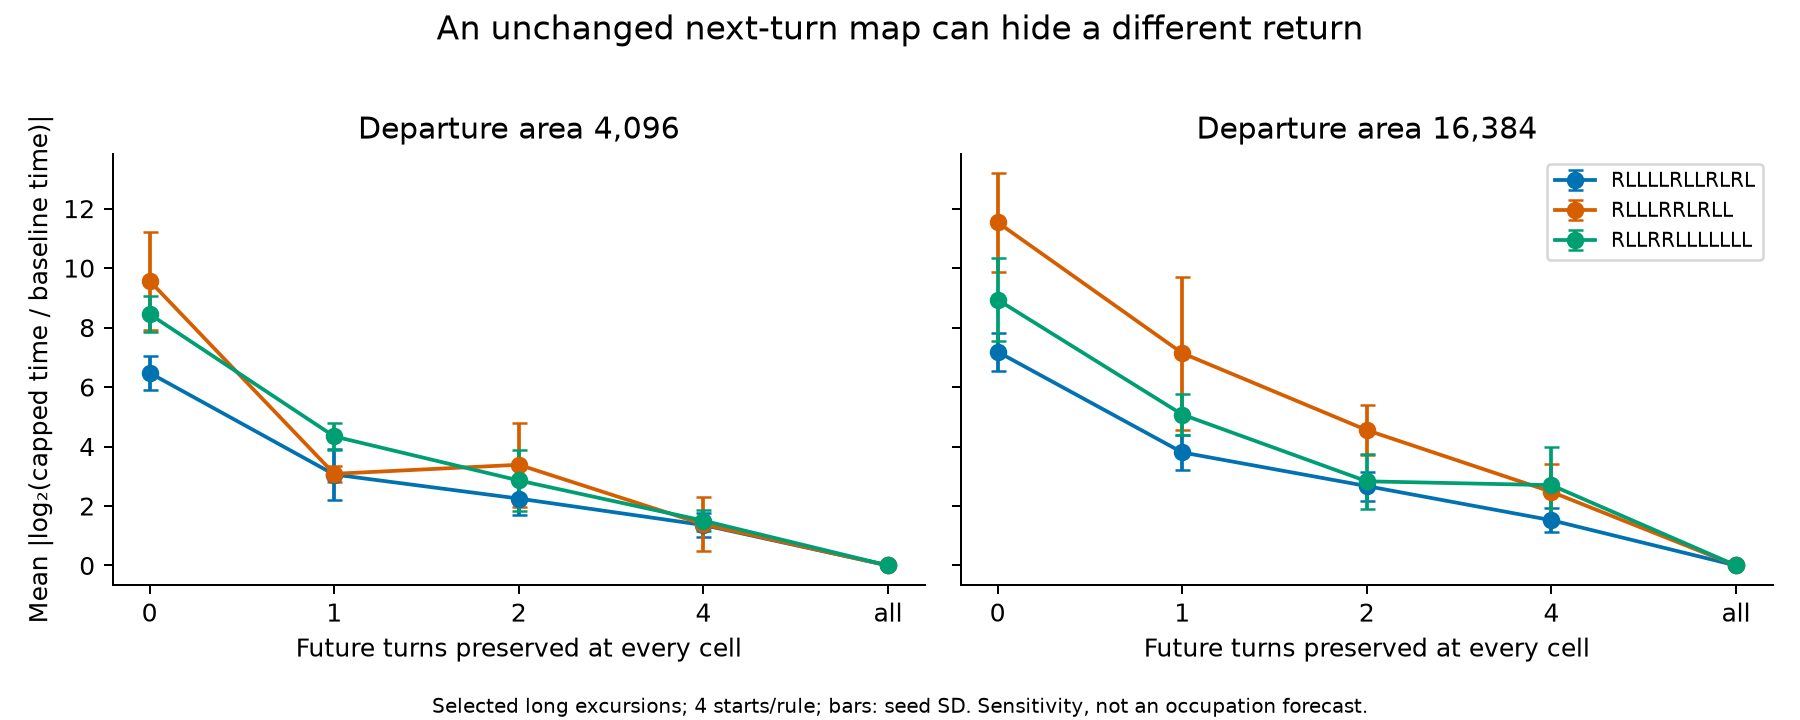

# Supplementary descriptive results

Added after the frozen primary analysis. Equal start weights for effects and outcome rates;
pooled replica medians for fractions of edited cells. No new hypothesis test.

| Rule | Area | k=1 signed log2 ratio | Factor-two change | Whole-field edits | Baseline-read edits |
|---|---:|---:|---:|---:|---:|
| RLLLLRLLRLRL | 4096 | -2.696 | 0.829 | 0.809 | 0.820 |
| RLLLLRLLRLRL | 16384 | -3.197 | 0.892 | 0.805 | 0.817 |
| RLLLRRLRLL | 4096 | -2.321 | 0.792 | 0.554 | 0.755 |
| RLLLRRLRLL | 16384 | -6.277 | 0.961 | 0.556 | 0.773 |
| RLLRRLLLLLLL | 4096 | -3.756 | 0.956 | 0.732 | 0.784 |
| RLLRRLLLLLLL | 16384 | -3.606 | 0.922 | 0.710 | 0.783 |

Minimum episode gate failed in 17/24 start/area groups.
All 640 k=1 paths and return tuples differ; all 640 k=n shams match.
Whole-field edits count colour labels, not instructions that the trajectory actually reads.
Negative signed effects describe these selected long baselines; they do not estimate the effect on ordinary departures.

## Episode support by start

| Rule | Seed | Area | Sampled long episodes |
|---|---:|---:|---:|
| RLLLLRLLRLRL | 2026102301 | 4096 | 2 |
| RLLLLRLLRLRL | 2026102301 | 16384 | 16 |
| RLLLLRLLRLRL | 2026102302 | 4096 | 4 |
| RLLLLRLLRLRL | 2026102302 | 16384 | 16 |
| RLLLLRLLRLRL | 2026102303 | 4096 | 16 |
| RLLLLRLLRLRL | 2026102303 | 16384 | 14 |
| RLLLLRLLRLRL | 2026102304 | 4096 | 11 |
| RLLLLRLLRLRL | 2026102304 | 16384 | 16 |
| RLLLRRLRLL | 2026102301 | 4096 | 3 |
| RLLLRRLRLL | 2026102301 | 16384 | 5 |
| RLLLRRLRLL | 2026102302 | 4096 | 2 |
| RLLLRRLRLL | 2026102302 | 16384 | 5 |
| RLLLRRLRLL | 2026102303 | 4096 | 2 |
| RLLLRRLRLL | 2026102303 | 16384 | 2 |
| RLLLRRLRLL | 2026102304 | 4096 | 1 |
| RLLLRRLRLL | 2026102304 | 16384 | 9 |
| RLLRRLLLLLLL | 2026102301 | 4096 | 2 |
| RLLRRLLLLLLL | 2026102301 | 16384 | 4 |
| RLLRRLLLLLLL | 2026102302 | 4096 | 1 |
| RLLRRLLLLLLL | 2026102302 | 16384 | 5 |
| RLLRRLLLLLLL | 2026102303 | 4096 | 5 |
| RLLRRLLLLLLL | 2026102303 | 16384 | 6 |
| RLLRRLLLLLLL | 2026102304 | 4096 | 6 |
| RLLRRLLLLLLL | 2026102304 | 16384 | 7 |


In [3]:
display(Image(filename=str(here / 'results/phase_effect.png')))
display(Markdown((here / 'results/details.md').read_text()))


## What the failed gate means

All 12 starts reached both bands. No baseline overflow, unfinished excursion,
board escape or censored replay occurred. The cap therefore did not truncate
any observed return. The failure is **sparse long-episode support**, not censoring.
Some start means use one episode. Four-start bootstrap intervals have weak
coverage information and no between-rule interpretation. The six area/rule
comparisons are not independent replications.

Each mean gives equal weight to starts, as registered. Long baseline selection
means signed shortening is not an estimate for ordinary departures. Different
prefix lengths change the permitted permutations and their support; ratios are
not fractions of information or additive causal contributions.

In [4]:
witness = json.loads((here / 'results/witness.json').read_text())
row = witness['row']
print(witness['selection'])
print('Rule:', row['rule'], 'seed:', row['seed'], 'departure time:', row['t0'])
print('Return:', row['base_t'], '->', row['arm_t'], 'steps')
print('First split: step', row['split_step'], 'on source visit', row['split_visit'])
print('Source phase words:', witness['split_source_future_turns'])
print('Independent sparse replay:', witness['independent_sparse_replay'])


Post hoc maximum base_t / arm_t among all k=1 rows; not representative
Rule: RLLLRRLRLL seed: 2026102304 departure time: 759018
Return: 86030 -> 6 steps
First split: step 6 on source visit 2
Source phase words: ['RLRLLRLLLR', 'RRLRLLRLLL']
Independent sparse replay: passed


## A counterexample, not a representative effect

The selected 86,030-to-6-step example was checked from the initial patch by a
separate sparse Python implementation (`scripts/check_witness.py`). On the first
read, the relevant phases both say R. On the second, one says L and the other R.
All initial turn directions remain the same. However, 10,418 interior colours
were shuffled; this does not assign the entire effect to one cell.

The exact same-map counterexample concerns edited fields, not necessarily fields
reachable from the natural patched-start distribution. All 640 k=1 replays changed
the path and return tuple, while all 640 full-word controls matched. Whole-field
phase organisation and individual phase values changed together.

## Validation and next decision

The Rust instrument has independent full-path sparse-oracle tests, an equivalent
RLRL-phase control, a known one-step return and a delayed-divergence check.
Live/cropped controls compare exact returns, not every live step. The full CPU
release suite and three known-answer analysis tests passed; all CSV bytes match
at one and three threads. GPU behavior is outside scope.

Stop the pilot as registered. No dead-end signature or family exclusion follows
from a failed support gate. A future design must secure enough long episodes
before confirmation and distinguish single-cell delayed effects from collective
phase organisation. It still needs an independent occupation prediction against
persistence. No such confirmation study is run here.